# SpaceDX Tutorial - Single Gene using already pre-processed AD data from Miyoshi et al. (2024) https://doi.org/10.1038/s41588-024-01961-x

In [1]:
%matplotlib inline
import time
notebook_start = time.perf_counter()

In [2]:
%%time
from spacedx import SpaceDX
import scanpy as sc
from spacedx.utils import BinomialLik, get_results, prepare_general_model_input, prepare_gene_input
from _utils import plot_attention_spatial
import torch

torch.manual_seed(0);  # reproducible model initialization and sampling

CPU times: user 2.52 s, sys: 568 ms, total: 3.09 s
Wall time: 4.14 s


## Load and prepare data input

### specify gene x and latent representation Z

In [3]:
%%time
gene = "Arrb2"
latent_representation = "X_staligner_pcs"

CPU times: user 1 μs, sys: 0 ns, total: 1 μs
Wall time: 3.1 μs


### load data & prepare model input

In [4]:
%%time
ad = sc.read("../data/demo_subset.h5ad")
y, F, Ls, R = prepare_general_model_input(ad, latent=latent_representation)
xs = prepare_gene_input(ad, gene)

CPU times: user 1.97 s, sys: 947 ms, total: 2.92 s
Wall time: 3.12 s


## Fit model

In [5]:
%%time
spacedx = SpaceDX(
    y,
    F,
    xs,
    Ls,
    R=R,
    n_samples=128,
)
spacedx.optimize()

CPU times: user 35.3 s, sys: 10.4 s, total: 45.7 s
Wall time: 17.8 s


(tensor(23.4090),
 tensor([ 2.6166e-05, -1.3827e-05,  1.4700e-05,  1.7619e-05, -2.4309e-06,
         -1.0023e-05, -8.0642e-06,  8.0823e-06,  3.1425e-06, -1.3348e-05,
         -1.1633e-05,  1.1436e-06,  2.2727e-05,  5.0012e-06,  4.7987e-06,
         -1.4877e-05,  4.1483e-06,  3.4357e-05, -7.7055e-06, -2.1219e-05,
         -3.9295e-05,  8.6613e-06, -8.1443e-06, -1.6778e-05, -1.2965e-06,
          9.6553e-05,  1.0542e-05]),
 True)

## Use fitted model to obtain test statistic (IW-ELBO), effect size (beta) & attention maps

In [6]:
%%time
spacedx.iw_elbo

CPU times: user 17 s, sys: 5.72 s, total: 22.7 s
Wall time: 5.43 s


-22.819055880917322

In [7]:
%%time
spacedx.beta_posterior_m

CPU times: user 20 μs, sys: 14 μs, total: 34 μs
Wall time: 34.1 μs


1.6302629887468056

## Plot attention

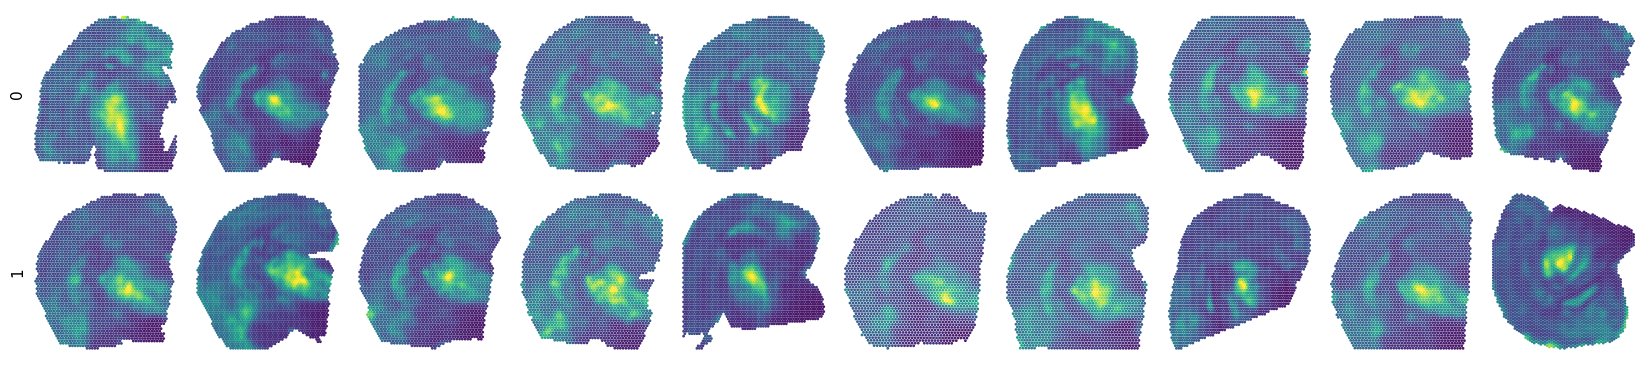

CPU times: user 1.33 s, sys: 195 ms, total: 1.53 s
Wall time: 1.11 s


In [8]:
%%time
attention_weights, _ = spacedx.get_attention_weights()
ad.obs["attention_weights"] = attention_weights
plot_attention_spatial(ad, random_state=0)

## Total run time

In [9]:
print(f"Total notebook run time: {time.perf_counter() - notebook_start:.1f} s")

Total notebook run time: 31.7 s
